Final Normalized Rayleigh Quotient of the learned weights: 0.6507


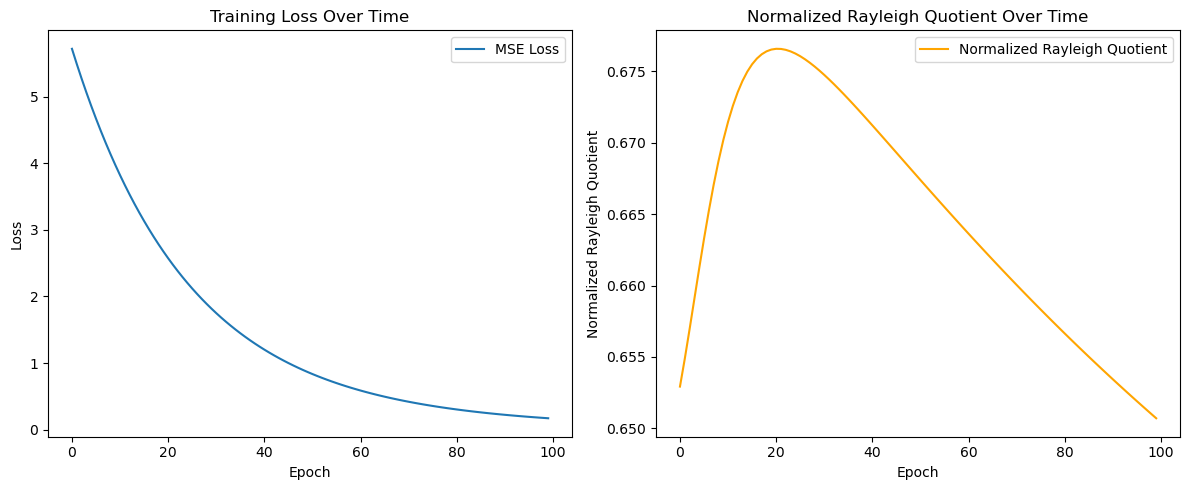

In [10]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
import matplotlib.pyplot as plt

# Generate synthetic data
def generate_synthetic_data(n_samples, n_features, noise_level=0.1):
    np.random.seed(42)
    X = np.random.randn(n_samples, n_features)
    W_true = np.random.randn(n_features, 1)
    Y = X @ W_true + noise_level * np.random.randn(n_samples, 1)
    return X, Y, W_true

# Standardize input data to have mean = 0 and variance = 1 for each feature
def standardize_data(X):
    mean = np.mean(X, axis=0)
    std = np.std(X, axis=0)
    X_standardized = (X - mean) / std
    return X_standardized

# Define a simple one-layer neural network
class OneLayerNN(nn.Module):
    def __init__(self, n_features):
        super(OneLayerNN, self).__init__()
        self.fc = nn.Linear(n_features, 1, bias=False)

    def forward(self, x):
        return self.fc(x)

# Function to compute normalized Rayleigh quotient
def compute_normalized_rayleigh_quotient(w, X):
    w = w.detach().numpy().flatten()
    A = X.T @ X
    numerator = w.T @ A @ w
    denominator = w.T @ w
    largest_eigenvalue = np.linalg.eigvalsh(A).max()
    return numerator / (denominator * largest_eigenvalue)

# Train the network and analyze performance
def train_and_analyze(n_samples, n_features, noise_level=0.1, learning_rate=0.01, epochs=100):
    # Generate data
    X, Y, W_true = generate_synthetic_data(n_samples, n_features, noise_level)

    # Standardize data
    X_standardized = standardize_data(X)
    
    X_tensor = torch.tensor(X_standardized, dtype=torch.float32)
    Y_tensor = torch.tensor(Y, dtype=torch.float32)

    # Initialize model, loss function, and optimizer
    model = OneLayerNN(n_features)
    criterion = nn.MSELoss()
    optimizer = optim.SGD(model.parameters(), lr=learning_rate)

    # Lists to store losses and RQ values
    losses = []
    rayleigh_quotients = []

    # Train the model
    for epoch in range(epochs):
        optimizer.zero_grad()
        outputs = model(X_tensor)
        loss = criterion(outputs, Y_tensor)
        loss.backward()
        optimizer.step()
        losses.append(loss.item())

        # Compute normalized Rayleigh quotient of the trained weights
        W_learned = model.fc.weight.data.view(-1)
        rayleigh_quotient = compute_normalized_rayleigh_quotient(W_learned, X_standardized)
        rayleigh_quotients.append(rayleigh_quotient)

    return losses, rayleigh_quotients, model.fc.weight.detach().numpy(), W_true

# Parameters
n_samples = 100
n_features = 10
noise_level = 0.1
learning_rate = 0.01
epochs = 100

# Run the training and analysis
losses, rayleigh_quotients, W_learned, W_true = train_and_analyze(n_samples, n_features, noise_level, learning_rate, epochs)

# Print final Rayleigh quotient
print(f'Final Normalized Rayleigh Quotient of the learned weights: {rayleigh_quotients[-1]:.4f}')

# Plot losses and Rayleigh quotients over epochs
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(losses, label='MSE Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss Over Time')
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(rayleigh_quotients, label='Normalized Rayleigh Quotient', color='orange')
plt.xlabel('Epoch')
plt.ylabel('Normalized Rayleigh Quotient')
plt.title('Normalized Rayleigh Quotient Over Time')
plt.legend()

plt.tight_layout()
plt.show()